<a href="https://colab.research.google.com/github/sumitpaul398/ML-projects/blob/main/Project1__Gas_Turbine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load data

In [ ]:
import sys
import os
import zipfile
import urllib.request

DOWNLOAD_ROOT = "https://archive.ics.uci.edu/ml/machine-learning-databases/00551/"
TURBINE_PATH =  os.path.join("Data Folder","Dataset")
TURBINE_URL = DOWNLOAD_ROOT + "pp_gas_emission.zip"

def fetch_turbine_data (turbine_url = TURBINE_URL, turbine_path = TURBINE_PATH):
  if not os.path.isdir(turbine_path):
    os.makedirs(turbine_path)
  zip_path = os.path.join(turbine_path, "pp_gas_emission.zip")
  urllib.request.urlretrieve(turbine_url, zip_path)
  with zipfile.ZipFile(zip_path,'r') as myzip:
    dataset_path = os.path.join(turbine_path, "Dataset")
    myzip.extractall('Datasets')


# download the file

In [ ]:
fetch_turbine_data()

# read the csv file

In [ ]:
import pandas as pd

dataset= pd.read_csv("Datasets/gt_2015.csv")

# use head to read a few lines

In [ ]:
dataset.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,1.95320,1020.1,84.985,2.5304,20.116,1048.7,544.92,116.27,10.799,7.4491,113.250
1,1.21910,1020.1,87.523,2.3937,18.584,1045.5,548.50,109.18,10.347,6.4684,112.020
2,0.94915,1022.2,78.335,2.7789,22.264,1068.8,549.95,125.88,11.256,3.6335,88.147
3,1.00750,1021.7,76.942,2.8170,23.358,1075.2,549.63,132.21,11.702,3.1972,87.078
4,1.28580,1021.6,76.732,2.8377,23.483,1076.2,549.68,133.58,11.737,2.3833,82.515


# use info() to get data structure

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7384 entries, 0 to 7383
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      7384 non-null   float64
 1   AP      7384 non-null   float64
 2   AH      7384 non-null   float64
 3   AFDP    7384 non-null   float64
 4   GTEP    7384 non-null   float64
 5   TIT     7384 non-null   float64
 6   TAT     7384 non-null   float64
 7   TEY     7384 non-null   float64
 8   CDP     7384 non-null   float64
 9   CO      7384 non-null   float64
 10  NOX     7384 non-null   float64
dtypes: float64(11)
memory usage: 634.7 KB


In [ ]:
dataset.describe()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
count,7384.000000,7384.00000,7384.000000,7384.000000,7384.000000,7384.000000,7384.000000,7384.000000,7384.000000,7384.000000,7384.000000
mean,17.225259,1014.50911,68.647464,3.598909,26.130149,1078.974689,546.642484,133.993380,12.097025,3.129986,59.890509
std,8.095783,6.89543,13.541116,0.610226,4.473737,19.762449,5.489066,16.179208,1.136601,2.234962,11.132464
min,-6.234800,989.40000,24.085000,2.368800,17.698000,1016.000000,516.040000,100.020000,9.870800,0.212800,25.905000
25%,11.073250,1009.67500,59.447250,3.117300,23.147000,1070.500000,544.747500,126.255000,11.465750,1.808175,52.399000
50%,17.456500,1014.00000,70.952000,3.538500,25.331000,1080.300000,549.720000,131.600000,11.933000,2.533400,56.838500
75%,23.684750,1018.30000,79.653750,4.194825,30.018250,1099.900000,550.030000,147.160000,13.148000,3.702550,65.093250
max,37.103000,1036.60000,96.666000,5.239500,40.716000,1100.400000,550.590000,179.500000,15.159000,41.097000,119.680000


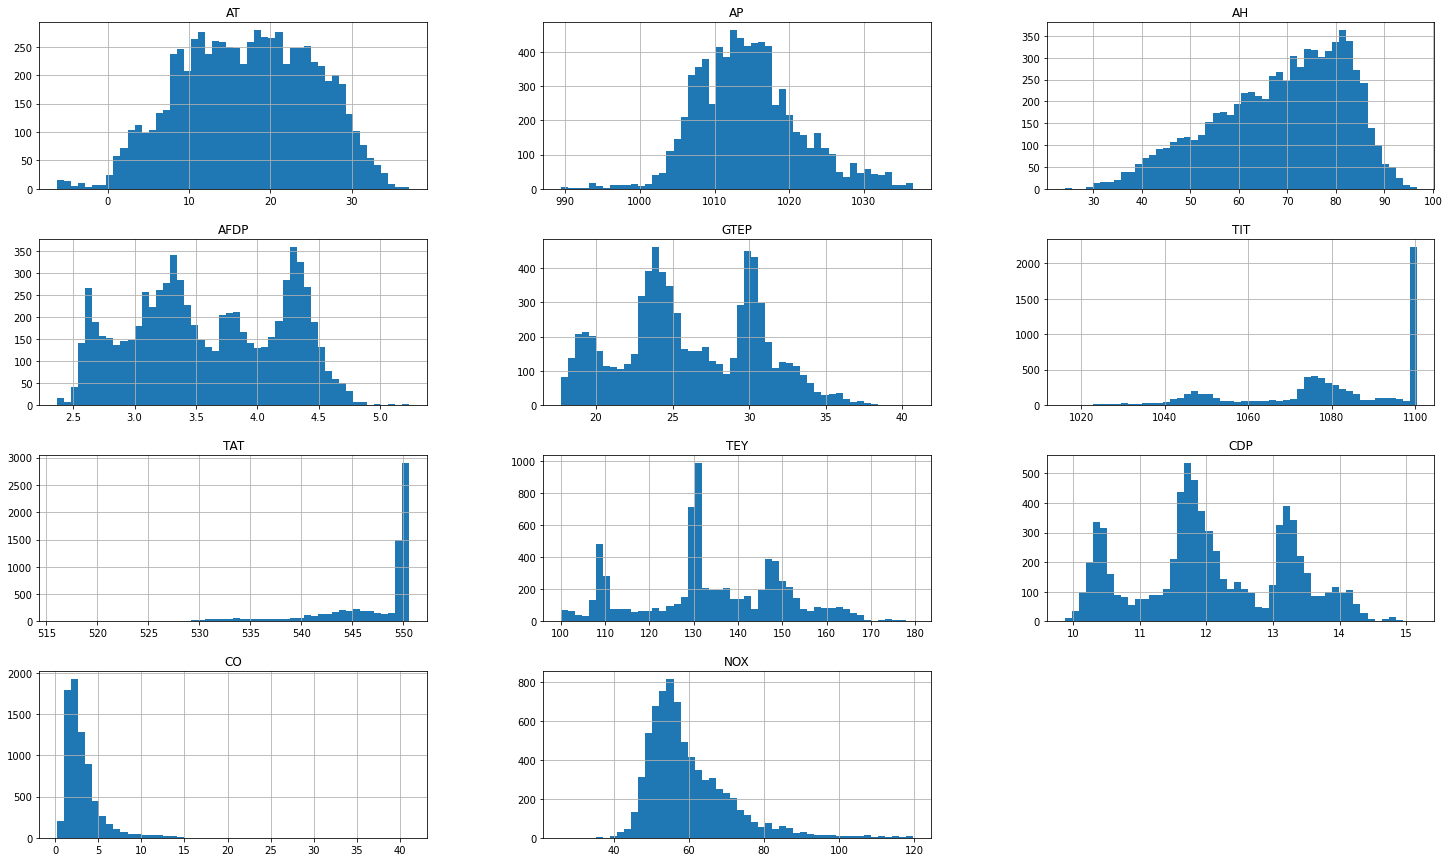

In [ ]:
import matplotlib.pyplot as plt
dataset.hist(bins = 50, figsize = (25,15))
plt.show()

# All the data are Float type and thus no encoding is required.

Extracting independent and dependent variables

In [ ]:
import numpy as np

X = dataset.iloc[:, :-2].values # Extracting the independent variables
print(X) # print independent variables

[[1.9532e+00 1.0201e+03 8.4985e+01 ... 5.4492e+02 1.1627e+02 1.0799e+01]
 [1.2191e+00 1.0201e+03 8.7523e+01 ... 5.4850e+02 1.0918e+02 1.0347e+01]
 [9.4915e-01 1.0222e+03 7.8335e+01 ... 5.4995e+02 1.2588e+02 1.1256e+01]
 ...
 [5.4820e+00 1.0285e+03 9.5219e+01 ... 5.4348e+02 1.0781e+02 1.0462e+01]
 [5.8837e+00 1.0287e+03 9.4200e+01 ... 5.5011e+02 1.3141e+02 1.1771e+01]
 [6.0392e+00 1.0288e+03 9.4547e+01 ... 5.4823e+02 1.2541e+02 1.1462e+01]]


In [ ]:
y1 = dataset.iloc[:,-2].values
y2 = dataset.iloc[:,-1].values
print(y1)
print(y2)

[ 7.4491  6.4684  3.6335 ... 11.414   3.3134 11.981 ]
[113.25  112.02   88.147 ...  96.147  64.738 109.24 ]


# split data into training set and test set

In [ ]:
from sklearn.model_selection import train_test_split

X1_train, X1_test, y1_train, y1_test = train_test_split(X, y1, test_size = 0.2, random_state = 0)

X2_train, X2_test, y2_train, y2_test = train_test_split(X, y2, test_size = 0.2, random_state = 0)

In [ ]:
print (X1_test)
print (y1_test)

[[  15.125 1020.1     74.117 ...  549.79   130.47    11.702]
 [  33.57  1008.2     39.263 ...  550.49   130.45    12.15 ]
 [  11.137 1009.6     62.082 ...  550.38   135.58    11.97 ]
 ...
 [  28.518 1010.      56.903 ...  536.09   153.22    13.824]
 [  10.87  1003.6     78.571 ...  549.9    111.84    10.405]
 [  28.313 1012.2     57.09  ...  544.06   148.54    13.221]]
[2.6847 1.9461 3.693  ... 1.6833 5.4816 2.0727]


In [ ]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()

regressor.fit(X1_train, y1_train)

LinearRegression()

In [ ]:
regressor.coef_

array([-5.80363918e-02,  1.86092220e-03, -1.43824489e-02,  3.18982985e-01,
        5.76266089e-02, -1.32265054e-01, -3.64614785e-02, -9.92157766e-02,
        1.93536820e+00])

In [ ]:
regressor.fit(X2_train, y2_train)

LinearRegression()

In [ ]:
regressor.coef_

array([-1.7634787 , -0.31488834, -0.31319927,  0.54440265,  0.30296806,
        1.17111869, -1.14226458, -2.72962447, 11.49079791])

# predict the test set results without feature scaling

In [ ]:
y1_predict = regressor.predict(X1_test)
print(y1_predict)

[58.62593695 55.35897981 66.1000122  ... 51.64400761 70.95461554
 47.13799523]


In [ ]:
y2_predict = regressor.predict(X2_test)
print(y2_predict)

[58.62593695 55.35897981 66.1000122  ... 51.64400761 70.95461554
 47.13799523]


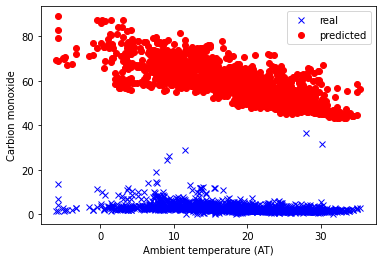

In [ ]:
plt.plot(X1_test[:, 0], y1_test,'bx') # May need to create plot for all variables
plt.plot(X1_test[:, 0],y1_predict,'ro')
plt.xlabel('Ambient temperature (AT)')
plt.ylabel('Carbion monoxide')
plt.legend(['real','predicted'])

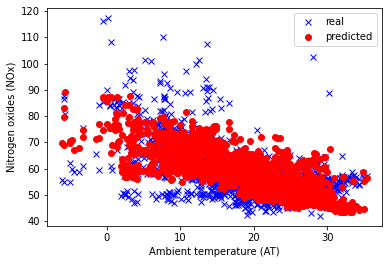

In [ ]:
plt.plot(X2_test[:, 0], y2_test,'bx') # May need to create plot for all variables
plt.plot(X2_test[:, 0],y2_predict,'ro')
plt.xlabel('Ambient temperature (AT)')
plt.ylabel('Nitrogen oxides (NOx)')
plt.legend(['real','predicted'])

Statiscial Analysis

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
print(f'mean squared error: {mean_squared_error(y1_test, y1_predict):.2f}')
print(f'coefficient of determination: {r2_score(y1_test, y1_predict):.2f}')

mean squared error: 3246.17
coefficient of determination: -527.46


In [ ]:
print(f'mean squared error: {mean_squared_error(y2_test, y2_predict):.2f}')
print(f'coefficient of determination: {r2_score(y2_test, y2_predict):.2f}')

mean squared error: 48.73
coefficient of determination: 0.56


# predict test results with feature scaling

In [ ]:
from sklearn.model_selection import train_test_split

X1_train, X1_test, y1_train, y1_test = train_test_split(X, y1, test_size = 0.2, random_state = 0)

X2_train, X2_test, y2_train, y2_test = train_test_split(X, y2, test_size = 0.2, random_state = 0)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler() #creating object

X1_train[:,0:] = sc.fit_transform(X1_train[:, 0:])
X1_test[:,0:] = sc.fit_transform(X1_test[:, 0:])

X2_train[:,0:] = sc.fit_transform(X2_train[:, 0:])
X2_test[:,0:] = sc.fit_transform(X2_test[:, 0:])

In [ ]:
regressor.fit(X1_train, y1_train)

LinearRegression()

In [ ]:
regressor.coef_

array([-0.46765097,  0.01284089, -0.19437443,  0.19514042,  0.25784659,
       -2.62978148, -0.19707449, -1.60754114,  2.20060903])

In [ ]:
regressor.fit(X2_train, y2_train)
regressor.coef_

array([-14.20992079,  -2.17281856,  -4.23279303,   0.33304272,
         1.35561127,  23.2849581 ,  -6.17394634, -44.22667221,
        13.06560354])

In [ ]:
y1_predict = regressor.predict(X1_test)
y2_predict = regressor.predict(X2_test)
print(y1_predict)
print(y2_predict)

[59.19800827 56.97988542 66.56555171 ... 52.0637125  70.68621667
 48.26871862]
[59.19800827 56.97988542 66.56555171 ... 52.0637125  70.68621667
 48.26871862]


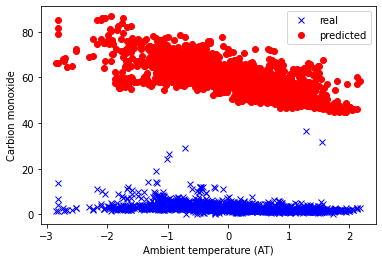

In [ ]:
plt.plot(X1_test[:, 0], y1_test,'bx') # May need to create plot for all variables
plt.plot(X1_test[:, 0],y1_predict,'ro')
plt.xlabel('Ambient temperature (AT)')
plt.ylabel('Carbion monoxide')
plt.legend(['real','predicted'])

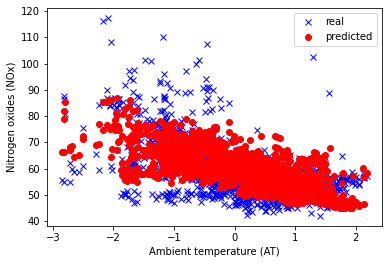

In [ ]:
plt.plot(X2_test[:, 0], y2_test,'bx') # May need to create plot for all variables
plt.plot(X2_test[:, 0],y2_predict,'ro')
plt.xlabel('Ambient temperature (AT)')
plt.ylabel('Nitrogen oxides (NOx)')
plt.legend(['real','predicted'])

In [ ]:
print(f'mean squared error: {mean_squared_error(y1_test, y1_predict):.2f}')
print(f'coefficient of determination: {r2_score(y1_test, y1_predict):.2f}')

mean squared error: 3286.41
coefficient of determination: -534.01


In [ ]:
print(f'mean squared error: {mean_squared_error(y2_test, y2_predict):.2f}')
print(f'coefficient of determination: {r2_score(y2_test, y2_predict):.2f}')

mean squared error: 48.37
coefficient of determination: 0.56


# backward elimination

In [ ]:
df = pd.read_csv("Datasets/gt_2015.csv")

In [ ]:
df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,1.95320,1020.1,84.985,2.5304,20.116,1048.7,544.92,116.27,10.799,7.4491,113.250
1,1.21910,1020.1,87.523,2.3937,18.584,1045.5,548.50,109.18,10.347,6.4684,112.020
2,0.94915,1022.2,78.335,2.7789,22.264,1068.8,549.95,125.88,11.256,3.6335,88.147
3,1.00750,1021.7,76.942,2.8170,23.358,1075.2,549.63,132.21,11.702,3.1972,87.078
4,1.28580,1021.6,76.732,2.8377,23.483,1076.2,549.68,133.58,11.737,2.3833,82.515


In [ ]:
X = df[["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]]
y1 = df['CO']
y2 = df['NOX']

In [ ]:
X1_train, X1_test, y1_train, y1_test = train_test_split(X, y1, test_size = 0.2, random_state = 0)

X2_train, X2_test, y2_train, y2_test = train_test_split(X, y2, test_size = 0.2, random_state = 0)

In [ ]:
print(X1_test)
print(X2_test)

          AT      AP      AH    AFDP    GTEP     TIT     TAT     TEY     CDP
6307  15.125  1020.1  74.117  3.3236  23.979  1077.1  549.79  130.47  11.702
5036  33.570  1008.2  39.263  4.0399  25.802  1085.0  550.49  130.45  12.150
1995  11.137  1009.6  62.082  3.3141  26.668  1080.6  550.38  135.58  11.970
4156  30.102  1005.7  56.180  4.2401  29.218  1099.8  548.08  145.39  12.957
6328  16.698  1022.5  58.083  2.5680  17.984  1030.5  542.61  100.71  10.148
...      ...     ...     ...     ...     ...     ...     ...     ...     ...
1632  15.686  1006.3  62.270  4.5395  36.405  1100.3  531.59  158.28  14.016
4640  24.067  1009.4  84.181  4.4254  29.931  1099.9  545.17  147.61  13.161
4021  28.518  1010.0  56.903  4.7726  32.695  1099.9  536.09  153.22  13.824
660   10.870  1003.6  78.571  2.7073  20.005  1048.7  549.90  111.84  10.405
4271  28.313  1012.2  57.090  4.3860  30.171  1100.0  544.06  148.54  13.221

[1477 rows x 9 columns]
          AT      AP      AH    AFDP    GTEP     TI

In [ ]:
Im = LinearRegression()
Im.fit(X1_train, y1_train)
Im.fit(X2_train, y2_train)
pred_y1 = Im.predict(X1_test)
pred_y2 = Im.predict(X1_test)

In [ ]:
import statsmodels.regression.linear_model as sm
ols_1 = sm.OLS(endog = y1, exog = X).fit()
ols_2 = sm.OLS(endog = y2, exog = X).fit()

In [ ]:
ols_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                     CO   R-squared (uncentered):                   0.869
Model:                            OLS   Adj. R-squared (uncentered):              0.869
Method:                 Least Squares   F-statistic:                              5440.
Date:                Tue, 11 Oct 2022   Prob (F-statistic):                        0.00
Time:                        16:33:14   Log-Likelihood:                         -12917.
No. Observations:                7384   AIC:                                  2.585e+04
Df Residuals:                    7375   BIC:                                  2.591e+04
Df Model:                           9                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
AT            -0.1603      0.007    -23.479      0.000      -0.174      -0.147
AP             0.0180      0.003      5.665      0.000       0.012       0.024
AH            -0.0148      0.002     -9.273      0.000      -0.018      -0.012
AFDP          -0.3013      0.117     -2.574      0.010      -0.531      -0.072
GTEP           0.0741      0.012      6.345      0.000       0.051       0.097
TIT            0.2052      0.019     10.661      0.000       0.167       0.243
TAT           -0.3377      0.027    -12.506      0.000      -0.391      -0.285
TEY           -0.5117      0.017    -30.374      0.000      -0.545      -0.479
CDP            1.6214      0.345      4.698      0.000       0.945       2.298
==============================================================================
Omnibus:                    10690.867   Durbin-Watson:                   1.073
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          8048029.340
Skew:                           8.359   Prob(JB):                         0.00
Kurtosis:                     163.869   Cond. No.                     3.39e+04
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 3.39e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
ols_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                    NOX   R-squared (uncentered):                   0.986
Model:                            OLS   Adj. R-squared (uncentered):              0.986
Method:                 Least Squares   F-statistic:                          5.947e+04
Date:                Tue, 11 Oct 2022   Prob (F-statistic):                        0.00
Time:                        16:33:14   Log-Likelihood:                         -24953.
No. Observations:                7384   AIC:                                  4.992e+04
Df Residuals:                    7375   BIC:                                  4.999e+04
Df Model:                           9                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
AT            -1.7482      0.035    -50.175      0.000      -1.816      -1.680
AP            -0.3241      0.016    -19.972      0.000      -0.356      -0.292
AH            -0.3083      0.008    -37.892      0.000      -0.324      -0.292
AFDP           0.1785      0.597      0.299      0.765      -0.993       1.350
GTEP           0.3004      0.060      5.038      0.000       0.184       0.417
TIT            1.1806      0.098     12.020      0.000       0.988       1.373
TAT           -1.1267      0.138     -8.174      0.000      -1.397      -0.856
TEY           -2.6965      0.086    -31.363      0.000      -2.865      -2.528
CDP           11.1485      1.761      6.329      0.000       7.696      14.601
==============================================================================
Omnibus:                     1391.163   Durbin-Watson:                   0.408
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4650.629
Skew:                           0.943   Prob(JB):                         0.00
Kurtosis:                       6.400   Cond. No.                     3.39e+04
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 3.39e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
X_back= np.append(arr = np.ones((7384,1)).astype(int), values = X, axis = 1)

In [ ]:
X_opt_1 = X_back[:, [0,1,2,3,4,5,6,7,8]]
X_opt_2 = X_back[:, [0,1,2,3,4,5,6,7,8]]

In [ ]:
print(X_opt_2[0])

[1.0000e+00 1.9532e+00 1.0201e+03 8.4985e+01 2.5304e+00 2.0116e+01
 1.0487e+03 5.4492e+02 1.1627e+02]


In [ ]:
ols = sm.OLS(endog = y1, exog = X_opt_1).fit()
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     CO   R-squared:                       0.641
Model:                            OLS   Adj. R-squared:                  0.641
Method:                 Least Squares   F-statistic:                     1647.
Date:                Tue, 11 Oct 2022   Prob (F-statistic):               0.00
Time:                        16:33:15   Log-Likelihood:                -12631.
No. Observations:                7384   AIC:                         2.528e+04
Df Residuals:                    7375   BIC:                         2.534e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.4461      6.095     24.846      0.000     139.497     163.395
x1            -0.0551      0.008     -7.126      0.000      -0.070      -0.040
x2             0.0027      0.003      0.856      0.392      -0.003       0.009
x3            -0.0167      0.002    -10.857      0.000      -0.020      -0.014
x4             0.3854      0.116      3.332      0.001       0.159       0.612
x5             0.0560      0.011      4.968      0.000       0.034       0.078
x6            -0.0599      0.018     -3.297      0.001      -0.096      -0.024
x7            -0.1416      0.020     -7.220      0.000      -0.180      -0.103
x8            -0.0729      0.024     -3.099      0.002      -0.119      -0.027
==============================================================================
Omnibus:                    10884.861   Durbin-Watson:                   1.097
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          9311307.027
Skew:                           8.624   Prob(JB):                         0.00
Kurtosis:                     176.109   Cond. No.                     6.20e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.2e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
ols = sm.OLS(endog = y2, exog = X_opt_2).fit()
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    NOX   R-squared:                       0.591
Model:                            OLS   Adj. R-squared:                  0.590
Method:                 Least Squares   F-statistic:                     1331.
Date:                Tue, 11 Oct 2022   Prob (F-statistic):               0.00
Time:                        16:33:15   Log-Likelihood:                -24973.
No. Observations:                7384   AIC:                         4.996e+04
Df Residuals:                    7375   BIC:                         5.003e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.2811     32.425      0.225      0.822     -56.282      70.844
x1            -1.7251      0.041    -41.915      0.000      -1.806      -1.644
x2            -0.3209      0.017    -19.318      0.000      -0.354      -0.288
x3            -0.3075      0.008    -37.641      0.000      -0.323      -0.291
x4             0.3554      0.615      0.578      0.564      -0.851       1.562
x5             0.3040      0.060      5.073      0.000       0.187       0.421
x6             1.6298      0.097     16.863      0.000       1.440       1.819
x7            -1.8122      0.104    -17.373      0.000      -2.017      -1.608
x8            -2.5980      0.125    -20.764      0.000      -2.843      -2.353
==============================================================================
Omnibus:                     1398.258   Durbin-Watson:                   0.406
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4701.656
Skew:                           0.946   Prob(JB):                         0.00
Kurtosis:                       6.421   Cond. No.                     6.20e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.2e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
X_opt_1 = X_back[:, [0,1,3,4,5,6,7,8]]
ols = sm.OLS(endog = y1, exog = X_opt_1).fit()
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     CO   R-squared:                       0.641
Model:                            OLS   Adj. R-squared:                  0.641
Method:                 Least Squares   F-statistic:                     1883.
Date:                Tue, 11 Oct 2022   Prob (F-statistic):               0.00
Time:                        16:33:15   Log-Likelihood:                -12631.
No. Observations:                7384   AIC:                         2.528e+04
Df Residuals:                    7376   BIC:                         2.533e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        152.5162      5.966     25.565      0.000     140.822     164.211
x1            -0.0587      0.006     -9.039      0.000      -0.071      -0.046
x2            -0.0171      0.001    -11.701      0.000      -0.020      -0.014
x3             0.3905      0.116      3.381      0.001       0.164       0.617
x4             0.0533      0.011      4.926      0.000       0.032       0.074
x5            -0.0537      0.017     -3.223      0.001      -0.086      -0.021
x6            -0.1486      0.018     -8.352      0.000      -0.184      -0.114
x7            -0.0809      0.022     -3.752      0.000      -0.123      -0.039
==============================================================================
Omnibus:                    10881.363   Durbin-Watson:                   1.097
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          9294411.575
Skew:                           8.619   Prob(JB):                         0.00
Kurtosis:                     175.951   Cond. No.                     4.67e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.67e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
X_opt_2 = X_back[:, [0,1,2,3,5,6,7,8]]
ols = sm.OLS(endog = y2, exog = X_opt_2).fit()
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    NOX   R-squared:                       0.591
Model:                            OLS   Adj. R-squared:                  0.590
Method:                 Least Squares   F-statistic:                     1521.
Date:                Tue, 11 Oct 2022   Prob (F-statistic):               0.00
Time:                        16:33:15   Log-Likelihood:                -24973.
No. Observations:                7384   AIC:                         4.996e+04
Df Residuals:                    7376   BIC:                         5.002e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9439     31.542      0.093      0.926     -58.888      64.776
x1            -1.7191      0.040    -43.189      0.000      -1.797      -1.641
x2            -0.3204      0.017    -19.315      0.000      -0.353      -0.288
x3            -0.3059      0.008    -39.561      0.000      -0.321      -0.291
x4             0.2984      0.059      5.046      0.000       0.182       0.414
x5             1.6480      0.091     18.043      0.000       1.469       1.827
x6            -1.8357      0.096    -19.122      0.000      -2.024      -1.648
x7            -2.6110      0.123    -21.220      0.000      -2.852      -2.370
==============================================================================
Omnibus:                     1401.516   Durbin-Watson:                   0.406
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4710.533
Skew:                           0.948   Prob(JB):                         0.00
Kurtosis:                       6.423   Cond. No.                     6.03e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.03e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
from sklearn.model_selection import train_test_split

X1_train, X1_test, y1_train, y1_test = train_test_split(X_opt_1, y1, test_size = 0.2, random_state = 0)

X2_train, X2_test, y2_train, y2_test = train_test_split(X_opt_2, y2, test_size = 0.2, random_state = 0)

In [ ]:
print(X1_test[0:2])

[[1.0000e+00 1.5125e+01 7.4117e+01 3.3236e+00 2.3979e+01 1.0771e+03
  5.4979e+02 1.3047e+02]
 [1.0000e+00 3.3570e+01 3.9263e+01 4.0399e+00 2.5802e+01 1.0850e+03
  5.5049e+02 1.3045e+02]]


In [ ]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()

regressor.fit(X1_train, y1_train)

LinearRegression()

In [ ]:
regressor.coef_

array([ 0.        , -0.0577786 , -0.01459105,  0.34870145,  0.05644087,
       -0.0465978 , -0.16405991, -0.09217269])

In [ ]:
y1_predict = regressor.predict(X1_test)
print(y1_predict)

[2.83982841 2.15420417 2.66341957 ... 2.40263945 5.60399513 1.25364167]


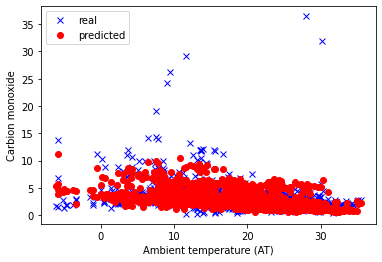

In [ ]:
plt.plot(X1_test[:, 1], y1_test,'bx') # May need to create plot for all variables
plt.plot(X1_test[:, 1],y1_predict,'ro')
plt.xlabel('Ambient temperature (AT)')
plt.ylabel('Carbion monoxide')
plt.legend(['real','predicted'])

In [ ]:
print(f'mean squared error: {mean_squared_error(y1_test, y1_predict):.2f}')
print(f'coefficient of determination: {r2_score(y1_test, y1_predict):.2f}')

mean squared error: 3.49
coefficient of determination: 0.43


In [ ]:
regressor.fit(X2_train, y2_train)
regressor.coef_

array([ 0.        , -1.73150221, -0.31109741, -0.30945933,  0.29910316,
        1.68244077, -1.90815692, -2.67065695])

In [ ]:
y2_predict = regressor.predict(X2_test)
print(y2_predict)

[59.72398948 54.82863656 65.5400477  ... 51.35403415 71.42079467
 47.6706805 ]


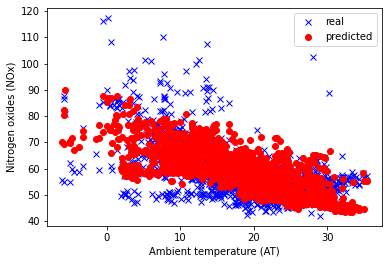

In [ ]:
plt.plot(X2_test[:, 1], y2_test,'bx') # May need to create plot for all variables
plt.plot(X2_test[:, 1],y2_predict,'ro')
plt.xlabel('Ambient temperature (AT)')
plt.ylabel('Nitrogen oxides (NOx)')
plt.legend(['real','predicted'])

In [ ]:
print(f'mean squared error: {mean_squared_error(y2_test, y2_predict):.2f}')
print(f'coefficient of determination: {r2_score(y2_test, y2_predict):.2f}')

mean squared error: 48.90
coefficient of determination: 0.56


# Polynomial Regression

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly_reg = PolynomialFeatures(degree = 2)
X_poly = poly_reg.fit_transform(X)

In [ ]:
print(X_poly[0:2,:])

[[1.00000000e+00 1.95320000e+00 1.02010000e+03 8.49850000e+01
  2.53040000e+00 2.01160000e+01 1.04870000e+03 5.44920000e+02
  1.16270000e+02 1.07990000e+01 3.81499024e+00 1.99245932e+03
  1.65992702e+02 4.94237728e+00 3.92905712e+01 2.04832084e+03
  1.06433774e+03 2.27098564e+02 2.10926068e+01 1.04060401e+06
  8.66931985e+04 2.58126104e+03 2.05203316e+04 1.06977887e+06
  5.55872892e+05 1.18607027e+05 1.10160599e+04 7.22245022e+03
  2.15046044e+02 1.70955826e+03 8.91237695e+04 4.63100262e+04
  9.88120595e+03 9.17753015e+02 6.40292416e+00 5.09015264e+01
  2.65363048e+03 1.37886557e+03 2.94209608e+02 2.73257896e+01
  4.04653456e+02 2.10956492e+04 1.09616107e+04 2.33888732e+03
  2.17232684e+02 1.09977169e+06 5.71457604e+05 1.21932349e+05
  1.13249113e+04 2.96937806e+05 6.33578484e+04 5.88459108e+03
  1.35187129e+04 1.25559973e+03 1.16618401e+02]
 [1.00000000e+00 1.21910000e+00 1.02010000e+03 8.75230000e+01
  2.39370000e+00 1.85840000e+01 1.04550000e+03 5.48500000e+02
  1.09180000e+02 1.034

In [ ]:
#from sklearn.model_selection import train_test_split

#X1_poly_train, X1_poly_test, y1_poly_train, y1_poly_test = train_test_split(X_poly, y1, test_size = 0.2, random_state = 0)
#X2_poly_train, X2_poly_test, y2_poly_train, y2_poly_test = train_test_split(X_poly, y2, test_size = 0.2, random_state = 0)

In [ ]:
lin_reg_1 = LinearRegression()
lin_reg_1.fit(X_poly, y1)

lin_reg_2 = LinearRegression()
lin_reg_2.fit(X_poly, y2)

X_poly_new = poly_reg.fit_transform(X)
y1_poly_pred = lin_reg_1.predict(X_poly_new)
y2_poly_pred = lin_reg_2.predict(X_poly_new)

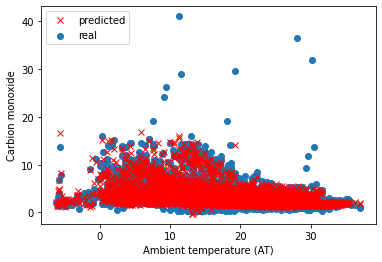

In [ ]:
plt.scatter(X['AT'],y1)
plt.plot(X['AT'], y1_poly_pred, 'rx')
plt.xlabel('Ambient temperature (AT)')
plt.ylabel('Carbion monoxide')
plt.legend(["predicted","real"])

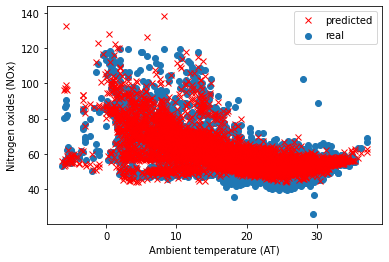

In [ ]:
plt.scatter(X['AT'],y2)
plt.plot(X['AT'], y2_poly_pred, 'rx')
plt.xlabel('Ambient temperature (AT)')
plt.ylabel('Nitrogen oxides (NOx)')
plt.legend(["predicted","real"])

Statistical Analysis

In [ ]:
print(f'mean squared error: {mean_squared_error(y1_poly_test,y1_poly_pred):.2f}')
print(f'coefficient of determination: {r2_score(y1_poly_test,y1_poly_pred):.2f}')

NameError: ignored